### Socket Programming

A socket is an endpoint for network communication. When you create a socket, the OS allocates a file descriptor to manage it.

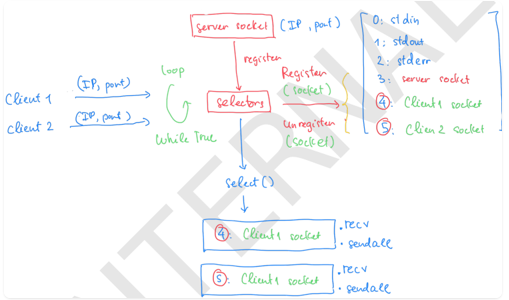

In Network program, Socket is like a two-ended "electrical outlet":
- One end is at the server (listening and waiting for a connection)
- One end is at the client (connecting to the server)

When the two ends are "plugged" together → data can flow back and forth (sending/receiving bytes).

```python
import socket

s = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
```
Where:
- `AF_INET`: Using IPv4 (like 127.0.0.1)
- `SOCK_STREAM`: Using TCP (UDP/IP layers also available)

#### ***Core Client-Server Flow***

**1. Server (passive) -> Create Socket -> Bind IP + Port -> Listen (wait for incoming connection) -> Accept -> get new socket for each client -> Send/receive on connected socket -> Close when done**

```python
import socket

HOST = "127.0.0.1"    # localhost (use "" or "0.0.0.0" to accept from anywhere)
PORT = 65432          # > 1023 is usually safe

with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
    s.bind((HOST, PORT))
    s.listen()                    # start listening (backlog default ~128)
    print(f"Server listening on {HOST}:{PORT}")

    while True:
        conn, addr = s.accept()   # blocks until client connects
        with conn:
            print(f"Connected by {addr}")
            while True:
                data = conn.recv(1024)   # max bytes to read at once
                if not data:
                    break
                print(f"Received: {data!r}")
                conn.sendall(data)       # echo back
```

**2. Client (active) -> Create socket -> Connect to server -> Send / receive -> Close**

```python
import socket

HOST = "127.0.0.1"
PORT = 65432

with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
    s.connect((HOST, PORT))
    s.sendall(b"Hello, world from client!")
    data = s.recv(1024)
    print(f"Received from server: {data!r}")
```

### Event Loop

An **Event Loop** is an infinite loop that monitors events (I/O, timers, callbacks) and dispatches them to their corresponding handlers.

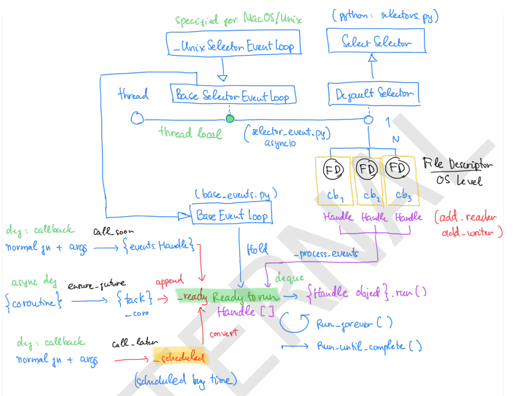

**Characteristics of Event Loop in Python:**
- Each event loop is attached to 1 thread
- Each thread has only 1 running loop at any given time
- You can create multiple loops but only 1 runs

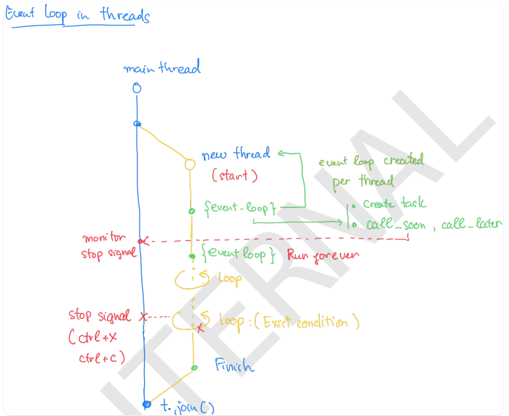

```python
import asyncio

# Get the current event loop (or create a new one)
loop = asyncio.get_event_loop()

# Or create a new loop
loop = asyncio.new_event_loop()
asyncio.set_event_loop(loop)

# Run a coroutine
async def async_fn():
    print("Hello from async")
    return "Done"

result = loop.run_until_complete(async_fn())
print(result)  # Done

***Recommend to use asyncio -> Better runtime and processing***